# 🔗 LIVE DEPLOYMENT LINK: https://co2emissionprediction-fhbcwjqnfbw49daen3qb8h.streamlit.app/

# CO₂ Emissions Prediction System
### AIC354 – Machine Learning Fundamentals | Assignment 3 – Task 2
**COMSATS University Islamabad, Lahore Campus** · Instructor: Dr. Rao Muhammad Adeel Nawab

> **Running on Google Colab:** `Runtime ▸ Run all`. When Step 2 asks, upload `CO2_Emissions_Canada.csv`.

---
## 1. Introduction
**Problem definition.** Given the specifications of a vehicle (make, class, engine size, cylinders, transmission, fuel type and fuel consumption), predict its tailpipe **CO₂ emissions in g/km**. This is a *supervised regression* problem, the same kind of task as the Car Price Prediction System.

**Application.** Regulators, manufacturers and buyers can estimate the emissions of a vehicle before testing it, compare models, and plan for carbon-tax or eco-labelling schemes.

**Aim.** Evaluate **five ML algorithms that were not used in the Car Price notebook** (Linear Regression, KNN, Decision Tree, Random Forest, Gradient Boosting) using **10-fold cross-validation on the full dataset**, pick the best one, save it, and deploy it as a cloud web app.

| # | Algorithm | Why it is different from Task 1 |
|---|-----------|--------------------------------|
| 1 | Ridge Regression | L2-regularised linear model |
| 2 | Support Vector Regression (RBF) | kernel-based, margin-based loss |
| 3 | AdaBoost Regressor | sequential boosting of shallow trees by re-weighting |
| 4 | Extra Trees Regressor | randomised-split tree ensemble |
| 5 | HistGradientBoosting Regressor | histogram-based boosting (LightGBM-style) |

**10-fold cross-validation.** The data is shuffled and split into 10 equal folds. Each fold is used once as the test set while the other 9 train the model, so every record is tested exactly once. The same folds are used for all algorithms for a fair comparison.

**Metric – RMSE** (lower is better, same unit as the target, g/km):
$$RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

**Input features (X)**

| Feature | Type | Description |
|---|---|---|
| Make | categorical | manufacturer (e.g. TOYOTA) |
| Vehicle Class | categorical | e.g. SUV - SMALL, COMPACT |
| Engine Size(L) | numeric | engine displacement |
| Cylinders | numeric | number of cylinders |
| Transmission | categorical | e.g. A6, M5, AS8 |
| Fuel Type | categorical | Z premium, X regular, D diesel, E ethanol, N natural gas |
| Fuel Consumption City / Hwy / Comb (L/100 km) | numeric | fuel consumption figures |

**Output (y):** `CO2 Emissions(g/km)` (numeric).

*Not used:* `Model` (≈2000 unique names, would explode the feature space and mostly identify single rows) and `Fuel Consumption Comb (mpg)` (an exact unit conversion of L/100 km, so it is redundant).

**Developer & system information**

| Item | Value |
|---|---|
| Student | *ABDUL MANAN* |
| Registration No. | FA24-BSE-001 |
| GitHub | [My GitHub Repo](https://github.com/mannan281928-debug/CO2_Emission_Prediction) |
| Course | AIC354 Machine Learning Fundamentals |
| Platform | Google Colab (Python 3) |
| Libraries | pandas, numpy, scikit-learn, matplotlib, tqdm |

**Table of contents:** 1 Imports · 2 Load data · 3 Understand & pre-process · 4 Features · 5 Preprocessing pipeline · 6 Algorithms · 7 K-Fold setup · 8 Cross-validation · 9 Results · 10 Save best model · 11 Application phase · 12 Feedback phase · Conclusion

## Step 1 – Import libraries

In [1]:
import time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
warnings.filterwarnings("ignore")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## Step 2 – Load the dataset (full dataset)

In [2]:
DATA_FILE = "CO2_Emissions_Canada.csv"
try:
    from google.colab import files
    import os
    if not os.path.exists(DATA_FILE):
        uploaded = files.upload()          # choose CO2_Emissions_Canada.csv
        DATA_FILE = list(uploaded.keys())[0]
except ImportError:
    pass                                    # running locally
df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
df.head()

Shape: (7385, 12)


,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


## Step 3 – Understand and pre-process the data

In [3]:
print(df.dtypes, "\n")
print("Missing values per column:\n", df.isnull().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

Make                                    str
Model                                   str
Vehicle Class                           str
Engine Size(L)                      float64
Cylinders                             int64
Transmission                            str
Fuel Type                               str
Fuel Consumption City (L/100 km)    float64
Fuel Consumption Hwy (L/100 km)     float64
Fuel Consumption Comb (L/100 km)    float64
Fuel Consumption Comb (mpg)           int64
CO2 Emissions(g/km)                   int64
dtype: object 

Missing values per column:
 Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissi

,count,mean,std,min,25%,50%,75%,max
Engine Size(L),7385.0,3.160068,1.354170,0.9,2.0,3.0,3.7,8.4
Cylinders,7385.0,5.615030,1.828307,3.0,4.0,6.0,6.0,16.0
Fuel Consumption City (L/100 km),7385.0,12.556534,3.500274,4.2,10.1,12.1,14.6,30.6
Fuel Consumption Hwy (L/100 km),7385.0,9.041706,2.224456,4.0,7.5,8.7,10.2,20.6
Fuel Consumption Comb (L/100 km),7385.0,10.975071,2.892506,4.1,8.9,10.6,12.6,26.1
Fuel Consumption Comb (mpg),7385.0,27.481652,7.231879,11.0,22.0,27.0,32.0,69.0
CO2 Emissions(g/km),7385.0,250.584699,58.512679,96.0,208.0,246.0,288.0,522.0


In [4]:
# Remove exact duplicates: identical rows could land in both train and test folds and inflate scores
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n0}  |  Duplicates removed: {n0-len(df)}  |  Rows after: {len(df)} (full dataset)")
print("Missing values after cleaning:", int(df.isnull().sum().sum()), " | Duplicates left:", int(df.duplicated().sum()))
print("\nDataset after pre-processing (first 10 rows):")
display(df.head(10))
print("Shape after pre-processing:", df.shape)

Rows before: 7385  |  Duplicates removed: 1103  |  Rows after: 6282 (full dataset)
Missing values after cleaning: 0  | Duplicates left: 0

Dataset after pre-processing (first 10 rows):


,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
5,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
6,ACURA,TL,MID-SIZE,3.5,6,AS6,Z,11.8,8.1,10.1,28,232
7,ACURA,TL AWD,MID-SIZE,3.7,6,AS6,Z,12.8,9.0,11.1,25,255
8,ACURA,TL AWD,MID-SIZE,3.7,6,M6,Z,13.4,9.5,11.6,24,267
9,ACURA,TSX,COMPACT,2.4,4,AS5,Z,10.6,7.5,9.2,31,212


Shape after pre-processing: (6282, 12)


### Save and download the pre-processed dataset

In [5]:
CLEAN_FILE = "Processed_CO2_Emissions_Canada.csv"
df.to_csv(CLEAN_FILE, index=False)
print("Saved", CLEAN_FILE, "-", df.shape[0], "rows x", df.shape[1], "columns")
try:
    from google.colab import files
    files.download(CLEAN_FILE)          # downloads the file to your computer
except ImportError:
    print("Running locally: the file is in the notebook folder.")

Saved Processed_CO2_Emissions_Canada.csv - 6282 rows x 12 columns
Running locally: the file is in the notebook folder.


## Step 4 – Features (X) and target (y)

In [6]:
TARGET = "CO2 Emissions(g/km)"
CAT = ["Make", "Vehicle Class", "Transmission", "Fuel Type"]
NUM = ["Engine Size(L)", "Cylinders", "Fuel Consumption City (L/100 km)",
       "Fuel Consumption Hwy (L/100 km)", "Fuel Consumption Comb (L/100 km)"]
X = df[CAT + NUM]
y = df[TARGET]
print("X:", X.shape, " y:", y.shape)
print("Target mean %.1f, min %d, max %d g/km" % (y.mean(), y.min(), y.max()))

X: (6282, 9)  y: (6282,)
Target mean 251.2, min 96, max 522 g/km


## Step 5 – Pre-processing pipeline
Imputation, scaling and one-hot encoding live **inside** the pipeline, so inside every CV fold they are fitted on the training part only (no data leakage). The same pipeline is saved with the model and reused by the web app.

In [7]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
])

## Step 6 – The five algorithms (none used in the Car Price notebook)

In [8]:
models = {
    "Ridge Regression":   Ridge(alpha=1.0),
    "SVR (RBF)":          SVR(kernel="rbf", C=100, epsilon=1.0),
    "AdaBoost":           AdaBoostRegressor(n_estimators=100, random_state=42),
    "Extra Trees":        ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42),
}
pipelines = {n: Pipeline([("prep", preprocessor), ("model", m)]) for n, m in models.items()}
list(pipelines)

['Ridge Regression',
 'SVR (RBF)',
 'AdaBoost',
 'Extra Trees',
 'HistGradientBoosting']

## Step 7 – 10-fold cross-validation setup

In [9]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
rows = [(i+1, len(tr), len(te)) for i, (tr, te) in enumerate(kf.split(X))]
pd.DataFrame(rows, columns=["Fold", "Train size", "Test size"]).set_index("Fold")

,Train size,Test size
Fold,,
1,5653,629
2,5653,629
3,5654,628
4,5654,628
5,5654,628
6,5654,628
7,5654,628
8,5654,628
9,5654,628


## Step 8 – Run the cross-validation

In [10]:
fold_rmse = {n: [] for n in pipelines}
fold_time = {n: 0.0 for n in pipelines}
splits = list(kf.split(X))
for name, pipe in tqdm(pipelines.items(), desc="Algorithms"):
    for tr, te in splits:
        t0 = time.time()
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        pred = m.predict(X.iloc[te])
        fold_rmse[name].append(np.sqrt(mean_squared_error(y.iloc[te], pred)))
        fold_time[name] += time.time() - t0
    print(f"{name:22s} mean RMSE = {np.mean(fold_rmse[name]):.3f}")

Algorithms:   0%|          | 0/5 [00:00<?, ?it/s]

Ridge Regression       mean RMSE = 5.288
SVR (RBF)              mean RMSE = 3.192
AdaBoost               mean RMSE = 15.199
Extra Trees            mean RMSE = 3.174
HistGradientBoosting   mean RMSE = 3.134


## Step 9 – Results

In [11]:
fold_df = pd.DataFrame(fold_rmse, index=[f"Fold {i}" for i in range(1, 11)])
fold_df.style.highlight_min(axis=1, color="#c8ebd2").format("{:.3f}").set_caption("RMSE per fold (g/km) – green = best algorithm in that fold")

,Ridge Regression,SVR (RBF),AdaBoost,Extra Trees,HistGradientBoosting
Fold 1,6.238,2.641,15.548,2.924,3.044
Fold 2,5.532,4.963,16.557,4.916,4.592
Fold 3,5.414,2.716,15.670,2.884,2.831
Fold 4,5.355,2.981,14.766,2.915,2.737
Fold 5,5.691,4.201,13.689,3.965,4.049
Fold 6,5.395,2.810,15.110,2.823,2.778
Fold 7,4.883,2.580,15.096,2.728,2.821
Fold 8,4.896,2.744,15.188,2.972,2.902
Fold 9,4.865,2.684,16.252,2.779,2.894
Fold 10,4.607,3.605,14.119,2.831,2.691


In [12]:
avg_y = y.mean()
summary = pd.DataFrame({
    "Mean RMSE": fold_df.mean(), "Std": fold_df.std(),
    "Best Fold": fold_df.min(), "Worst Fold": fold_df.max(),
    "RMSE as % of Avg CO2": fold_df.mean() / avg_y * 100,
    "Time (s)": pd.Series(fold_time),
}).sort_values("Mean RMSE")
summary.insert(0, "Rank", range(1, len(summary)+1))
summary.style.format({"Mean RMSE":"{:.3f}","Std":"{:.3f}","Best Fold":"{:.3f}","Worst Fold":"{:.3f}",
                      "RMSE as % of Avg CO2":"{:.2f}%","Time (s)":"{:.1f}"}).highlight_min(subset=["Mean RMSE"], color="#c8ebd2")

,Rank,Mean RMSE,Std,Best Fold,Worst Fold,RMSE as % of Avg CO2,Time (s)
HistGradientBoosting,1,3.134,0.646,2.691,4.592,1.25%,12.7
Extra Trees,2,3.174,0.708,2.728,4.916,1.26%,16.4
SVR (RBF),3,3.192,0.808,2.580,4.963,1.27%,29.4
Ridge Regression,4,5.288,0.485,4.607,6.238,2.11%,0.9
AdaBoost,5,15.199,0.879,13.689,16.557,6.05%,17.1


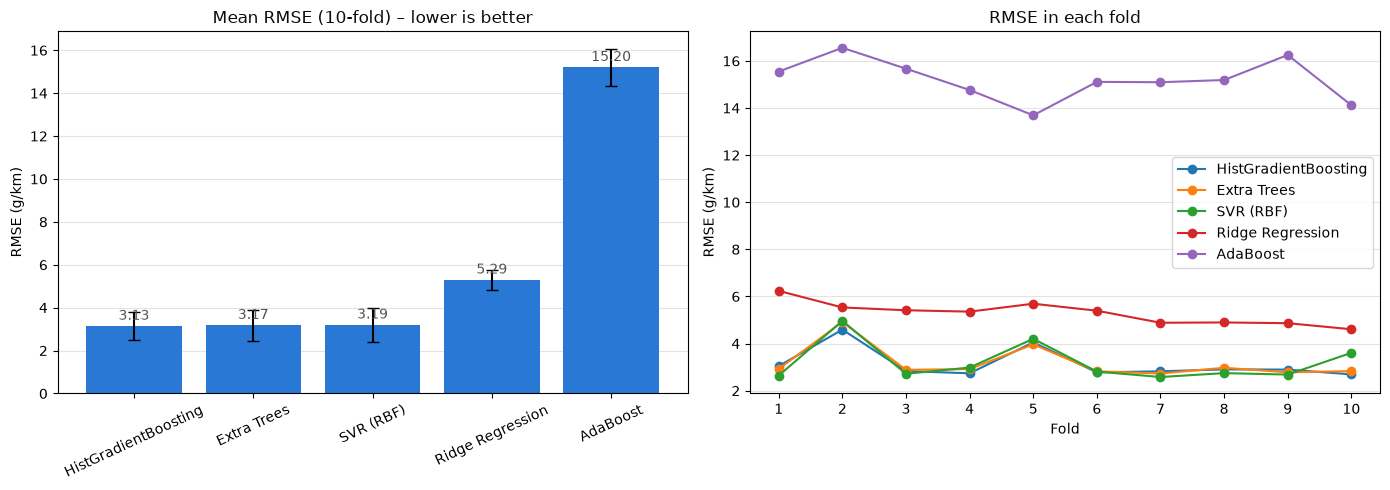

In [13]:
BAR, TEXT, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
order = summary.index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(order, summary["Mean RMSE"], yerr=summary["Std"], color=BAR, capsize=4)
ax[0].set_title("Mean RMSE (10-fold) – lower is better", color=TEXT)
ax[0].set_ylabel("RMSE (g/km)"); ax[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(summary["Mean RMSE"]): ax[0].text(i, v + 0.3, f"{v:.2f}", ha="center", color=MUTED)
for n in order: ax[1].plot(range(1, 11), fold_df[n], "o-", label=n)
ax[1].set_title("RMSE in each fold", color=TEXT); ax[1].set_xlabel("Fold"); ax[1].set_ylabel("RMSE (g/km)")
ax[1].set_xticks(range(1, 11)); ax[1].legend()
for a in ax: a.grid(color=GRID, axis="y"); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [14]:
best = summary.index[0]
print(f"Best algorithm: {best}  (mean RMSE {summary.loc[best,'Mean RMSE']:.3f} g/km, "
      f"{summary.loc[best,'RMSE as % of Avg CO2']:.2f}% of the average CO2)")
print(f"Worst algorithm: {summary.index[-1]}  ({summary['Mean RMSE'].iloc[-1]:.3f} g/km)")
print(f"Most stable (lowest Std): {summary['Std'].idxmin()}")

Best algorithm: HistGradientBoosting  (mean RMSE 3.134 g/km, 1.25% of the average CO2)
Worst algorithm: AdaBoost  (15.199 g/km)
Most stable (lowest Std): Ridge Regression


**Observations.**
* The Mean RMSE ranking above shows which model predicts CO₂ best; the % column shows the typical error relative to the average emission (~250 g/km).
* Tree-ensembles and boosting can capture the non-linear link between engine/fuel use and CO₂, while Ridge is a purely linear model. CO₂ is almost proportional to fuel consumption, so even linear models do well, and the gap between algorithms is mostly in the small residual errors.
* A small Std across folds means the result does not depend on which records were held out, so the ranking is reliable.

## Step 10 – Train the best model on all data and save it

In [15]:
final_model = clone(pipelines[best]).fit(X, y)
MODEL_FILE = "co2_model.pkl"
with open(MODEL_FILE, "wb") as f:
    pickle.dump({"model": final_model, "features": CAT + NUM, "name": best,
                 "sklearn_version": sklearn.__version__}, f)
print("Saved", MODEL_FILE, "using scikit-learn", sklearn.__version__)
try:
    from google.colab import files
    files.download(MODEL_FILE)
except ImportError:
    pass

Saved co2_model.pkl using scikit-learn 1.9.1


## Step 11 – Application phase (use the saved model)

In [16]:
example = pd.DataFrame([{
    "Make": "TOYOTA", "Vehicle Class": "COMPACT", "Transmission": "AS6", "Fuel Type": "X",
    "Engine Size(L)": 2.0, "Cylinders": 4,
    "Fuel Consumption City (L/100 km)": 8.5,
    "Fuel Consumption Hwy (L/100 km)": 6.0,
    "Fuel Consumption Comb (L/100 km)": 7.4,
}])
display(example.T)
with open(MODEL_FILE, "rb") as f: bundle = pickle.load(f)
pred = bundle["model"].predict(example[bundle["features"]])[0]
print(f"Predicted CO2 emissions: {pred:.1f} g/km  (model: {bundle['name']})")

,0
Make,TOYOTA
Vehicle Class,COMPACT
Transmission,AS6
Fuel Type,X
Engine Size(L),2.0
Cylinders,4
Fuel Consumption City (L/100 km),8.5
Fuel Consumption Hwy (L/100 km),6.0
Fuel Consumption Comb (L/100 km),7.4


Predicted CO2 emissions: 173.8 g/km  (model: HistGradientBoosting)


## Step 12 – Feedback phase
The deployed web app (link at the top) shows the prediction to the user. If a real measured value is later available, it can be compared with the prediction, and the model re-trained periodically with the new records.

## Conclusion
Five new algorithms were compared with 10-fold cross-validation on the full CO₂ emissions dataset. The best one (see Step 9) was trained on all records, saved as `co2_model.pkl` and deployed behind a Streamlit web app on the cloud.
